# Large-Scale Metaparameter Tuning and Comparison via Multi-Task Bayesian Optimization

This notebook evaluates payoff-based Nash Equilibrium seeking across an ensemble of 100 strongly monotone quadratic games ($N=2, m=1$) with interior equilibria.
Using active task-selecting Multi-Task Bayesian Optimization (MTBO, Swersky et al. 2013), we tune both **Zero-Order Gradient Play (`ZOGrandientPlay`)** with one-point estimation and **Continuous-Time Extremum Seeking (`NESeeking`)**.

### Workflow Outline:
1. **Ensemble Generation:** Sample 100 strongly monotone quadratic games ensuring strictly interior Nash equilibria.
2. **Automated Representative Selection:** Programmatically select 5 diverse games (Extreme ill-conditioned, Well-behaved/isotropic, Narrow action bounds, Highly asymmetric coupling, Boundary-adjacent equilibrium).
3. **ZOGrandientPlay MTBO:** Multi-Task Bayesian Optimization ($n_{\text{init}}=100, n_{\text{bo}}=700$, strictly 1-point estimation, $N_{\text{iter}}=3000, K=50$) to discover game-specific $\theta_j^*$ and universal default $\theta_{\text{default}}^*$.
4. **ZOGrandientPlay Action Trajectory Visualizations:** For the 5 representative games, plot 2x2 dedicated subplots comparing action convergence under Game Optima vs. Default Optima (Actions only).
5. **NESeeking MTBO:** Multi-Task Bayesian Optimization ($n_{\text{init}}=100, n_{\text{bo}}=700$, $N_{\text{iter}}=3000, K=50$) to discover game-specific $\theta_j^*$ and universal default $\theta_{\text{default}}^*$.
6. **NESeeking Action Trajectory Visualizations:** For the 5 representative games, plot 2x2 dedicated subplots comparing action convergence under Game Optima vs. Default Optima (Actions only).
7. **Quantitative Comparative Report:** Comparative table of True NE vs. Game-Specific Optima vs. Default Optima, tunability metrics, and ensemble statistics across all 100 games.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from payoffnash import (
    Game,
    QuadraticGame,
    generate_quadratic_games,
    MetaParamOptimization,
    ZOGrandientPlay,
    NESeeking,
)

# 1. Sample 100 strongly monotone quadratic games with N=2, m=1 and NE strictly in the interior
games = generate_quadratic_games(
    ensemble_size=100,
    N=2,
    m=1,
    alpha=0.05,
    enforce_interior=True,
    seed=42,
)

def compute_condition_number(game: QuadraticGame) -> float:
    H_sym = 0.5 * (game.H + game.H.T)
    w = np.linalg.eigvalsh(-H_sym)
    return float(w[-1] / max(w[0], 1e-12))

def compute_action_volume(game: QuadraticGame) -> float:
    vol = 1.0
    for s in game.action_sets:
        for iv in s:
            vol *= (iv[1] - iv[0])
    return float(vol)

def compute_skewness(game: QuadraticGame) -> float:
    return float(np.linalg.norm(game.H - game.H.T, ord="fro"))

def compute_boundary_distance(game: QuadraticGame) -> float:
    lb = np.array([[iv[0] for iv in s] for s in game.action_sets]).ravel()
    ub = np.array([[iv[1] for iv in s] for s in game.action_sets]).ravel()
    u_star = game.nash_equilibrium.ravel()
    return float(np.min(np.minimum(u_star - lb, ub - u_star)))

def select_representative_games(games: list[QuadraticGame]) -> list[tuple[int, str, QuadraticGame]]:
    cond_nums = [compute_condition_number(g) for g in games]
    vols = [compute_action_volume(g) for g in games]
    skews = [compute_skewness(g) for g in games]
    b_dists = [compute_boundary_distance(g) for g in games]

    selected_indices: set[int] = set()
    representative_games: list[tuple[int, str, QuadraticGame]] = []

    # 1. Ill-Conditioned (max kappa)
    idx_ill = int(np.argmax(cond_nums))
    selected_indices.add(idx_ill)
    representative_games.append((idx_ill, f"Extreme Ill-Conditioned (kappa={cond_nums[idx_ill]:.2f})", games[idx_ill]))

    # 2. Isotropic (min kappa)
    for idx in np.argsort(cond_nums):
        if idx not in selected_indices:
            selected_indices.add(int(idx))
            representative_games.append((int(idx), f"Well-Behaved / Isotropic (kappa={cond_nums[idx]:.2f})", games[idx]))
            break

    # 3. Narrow Bounds (min volume)
    for idx in np.argsort(vols):
        if idx not in selected_indices:
            selected_indices.add(int(idx))
            representative_games.append((int(idx), f"Narrow Action Bounds (vol={vols[idx]:.4f})", games[idx]))
            break

    # 4. Asymmetric Coupling (max skewness)
    for idx in np.argsort(skews)[::-1]:
        if idx not in selected_indices:
            selected_indices.add(int(idx))
            representative_games.append((int(idx), f"Highly Asymmetric Coupling (skew={skews[idx]:.3f})", games[idx]))
            break

    # 5. Boundary-Adjacent Equilibrium (min distance to boundary)
    for idx in np.argsort(b_dists):
        if idx not in selected_indices:
            selected_indices.add(int(idx))
            representative_games.append((int(idx), f"Boundary-Adjacent Equilibrium (dist={b_dists[idx]:.3f})", games[idx]))
            break

    return representative_games

rep_games = select_representative_games(games)
print(f"Generated {len(games)} strongly monotone quadratic games. Selected 5 representative games:")
for g_idx, category, g in rep_games:
    u_star = g.nash_equilibrium.ravel()
    print(f"  Game {g_idx:2d} | Category: {category:45s} | True NE: [{u_star[0]:.4f}, {u_star[1]:.4f}]")


Generated 100 strongly monotone quadratic games. Selected 5 representative games:
  Game 67 | Category: Extreme Ill-Conditioned (kappa=20.02)         | True NE: [0.9691, -0.0888]
  Game 27 | Category: Well-Behaved / Isotropic (kappa=1.06)         | True NE: [-0.5634, -0.3864]
  Game 65 | Category: Narrow Action Bounds (vol=0.1897)             | True NE: [-0.0151, 0.3119]
  Game 61 | Category: Highly Asymmetric Coupling (skew=2.715)       | True NE: [0.5663, -0.1706]
  Game 30 | Category: Boundary-Adjacent Equilibrium (dist=0.001)    | True NE: [0.4676, -0.6167]


In [2]:
# 2. ZOGrandientPlay MTBO (Strictly One-Point Estimation)
zo_search_space = {"v": (0.5, 10.0), "a": (0.01, 1.0)}
zo_fixed_params = {"estimation_type": "one-point", "epsilon": 1e-4}

zo_opt = MetaParamOptimization(
    game_ensemble=games,
    search_space=zo_search_space,
    algorithm_class=ZOGrandientPlay,
    output_path="zo_optimal_metaparams.csv",
    num_iters=3000,
    smoothing_window=50,
    n_init=100,
    n_bo_steps=700,
    seed=42,
    fixed_params=zo_fixed_params,
)

zo_results = zo_opt.run_optimization_loop()
print("ZOGrandientPlay MTBO complete.")
print("Universal default theta (average):", zo_results[-1])


ZOGrandientPlay MTBO complete.
Universal default theta (average): {'game_id': 'default', 'is_default': True, 'estimation_type': 'one-point', 'epsilon': 0.0001, 'v': 8.327157683842607, 'a': 0.7170269954611487, 'objective_value': 0.2388}


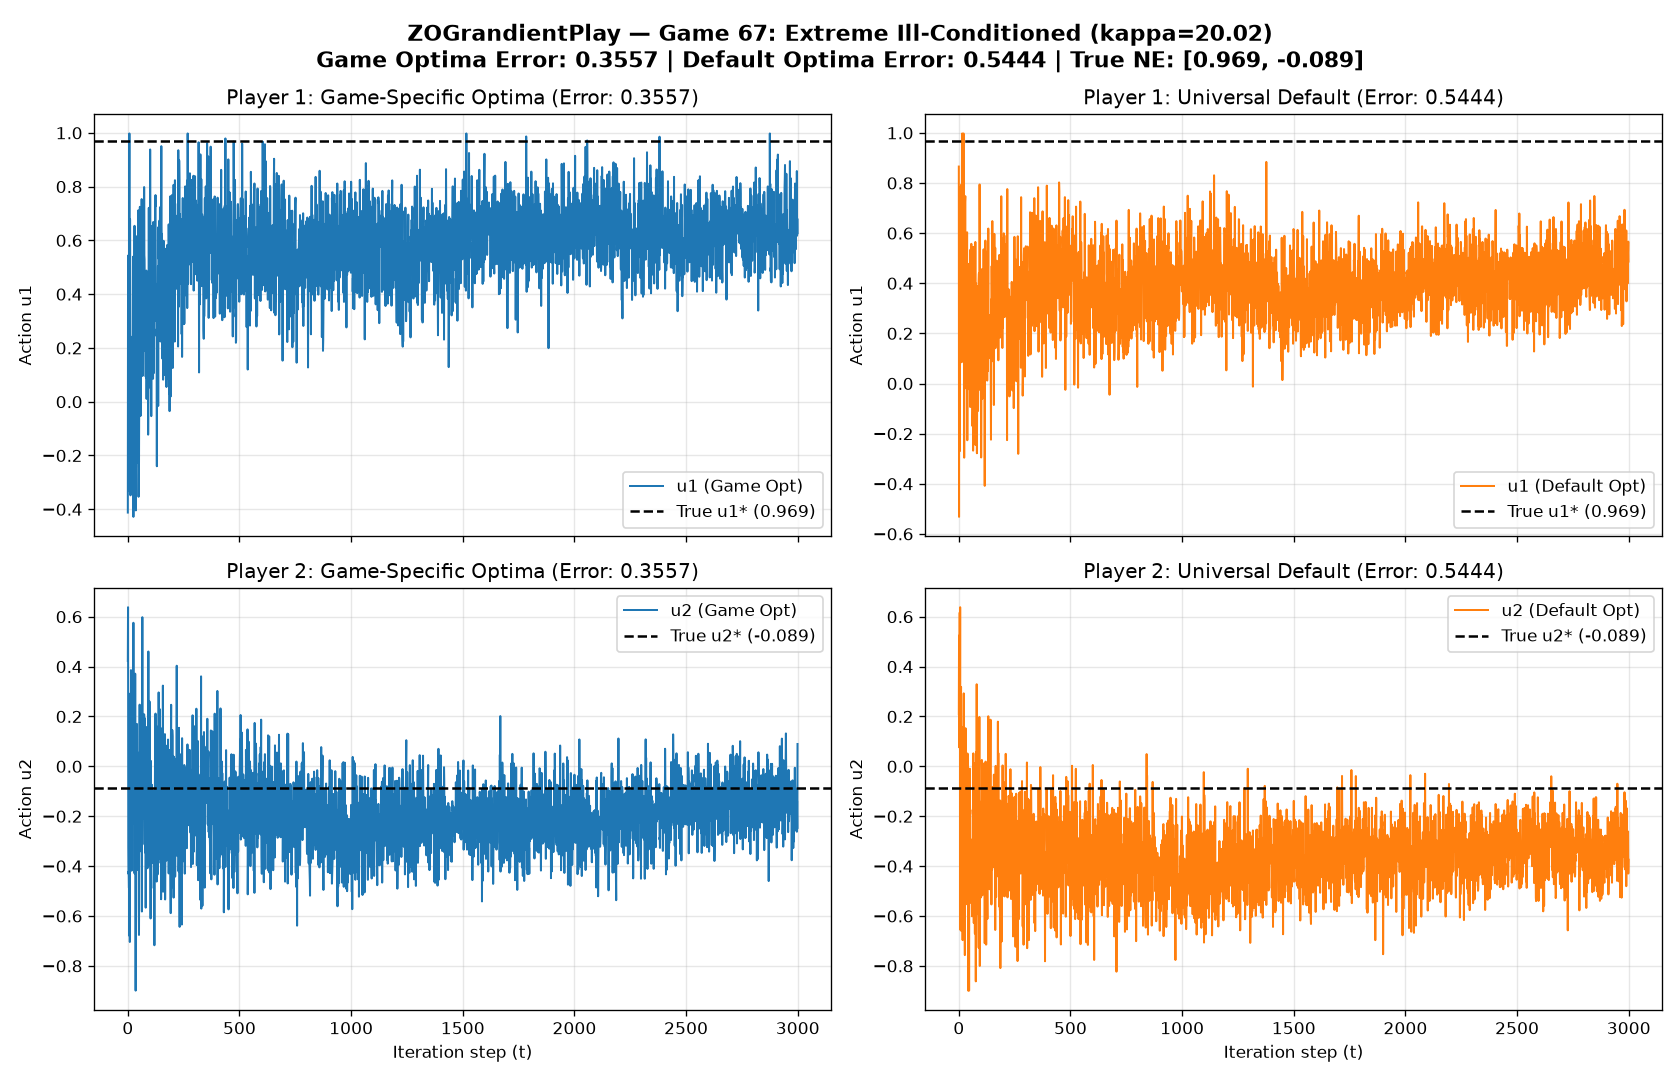

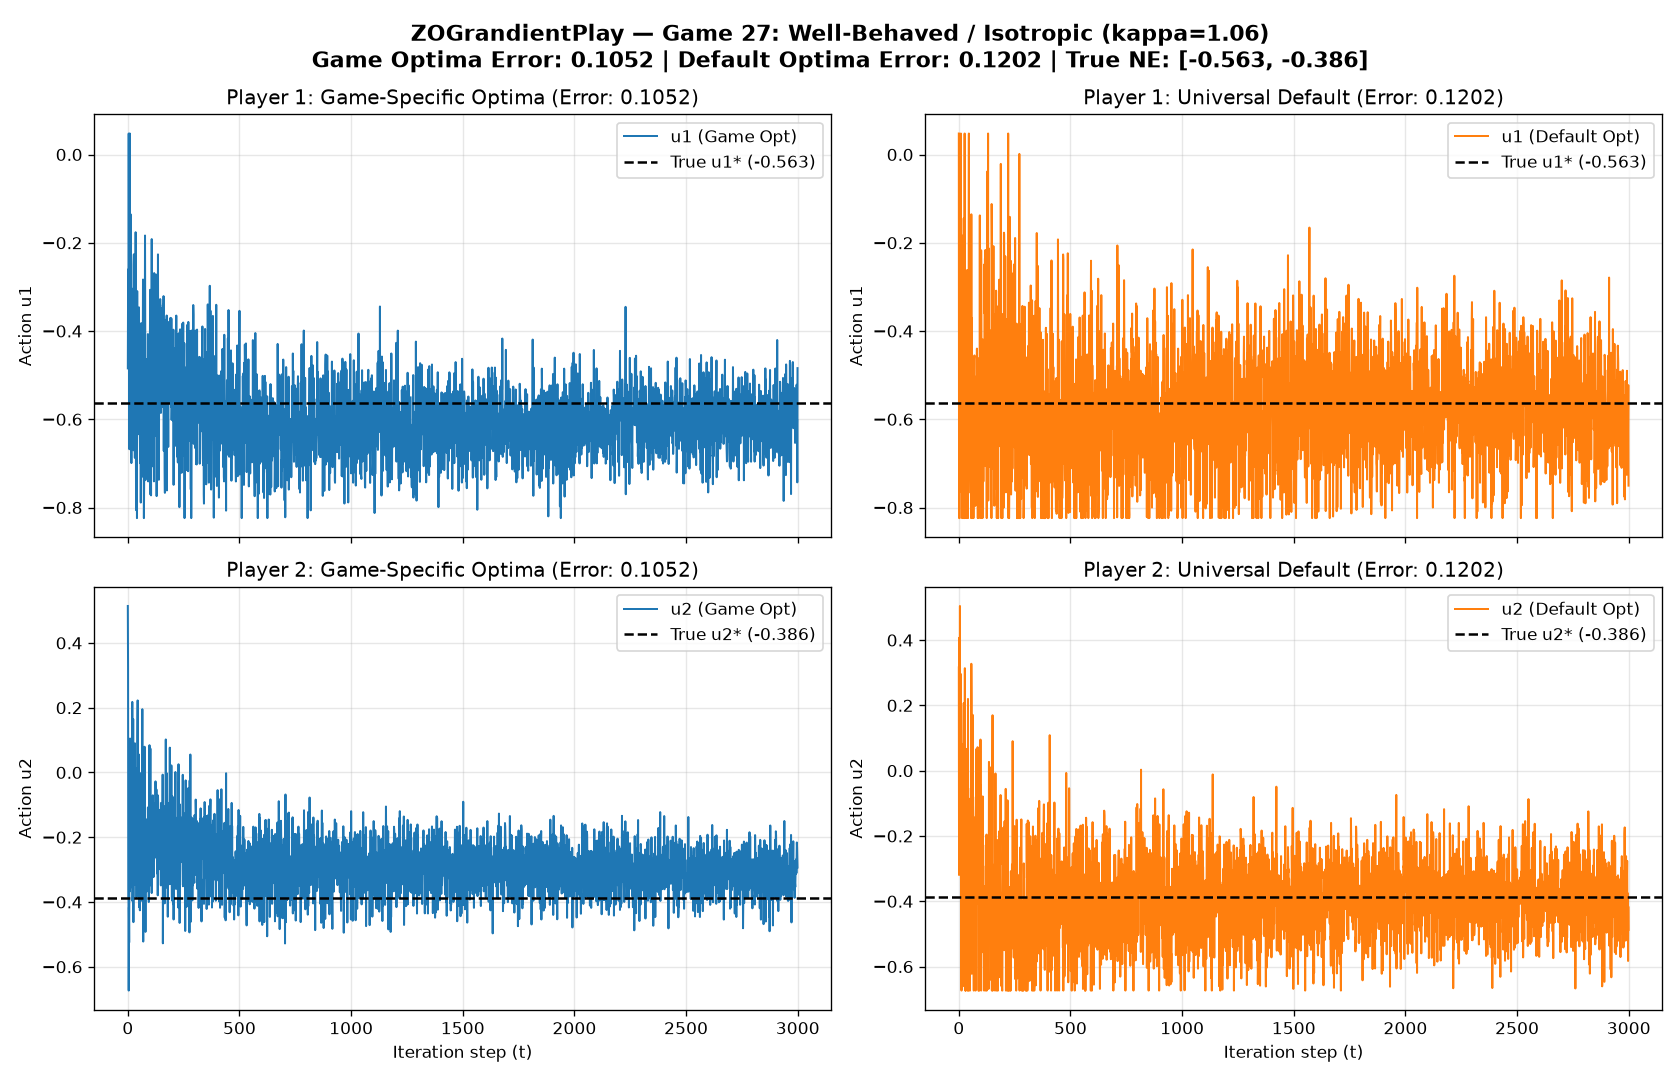

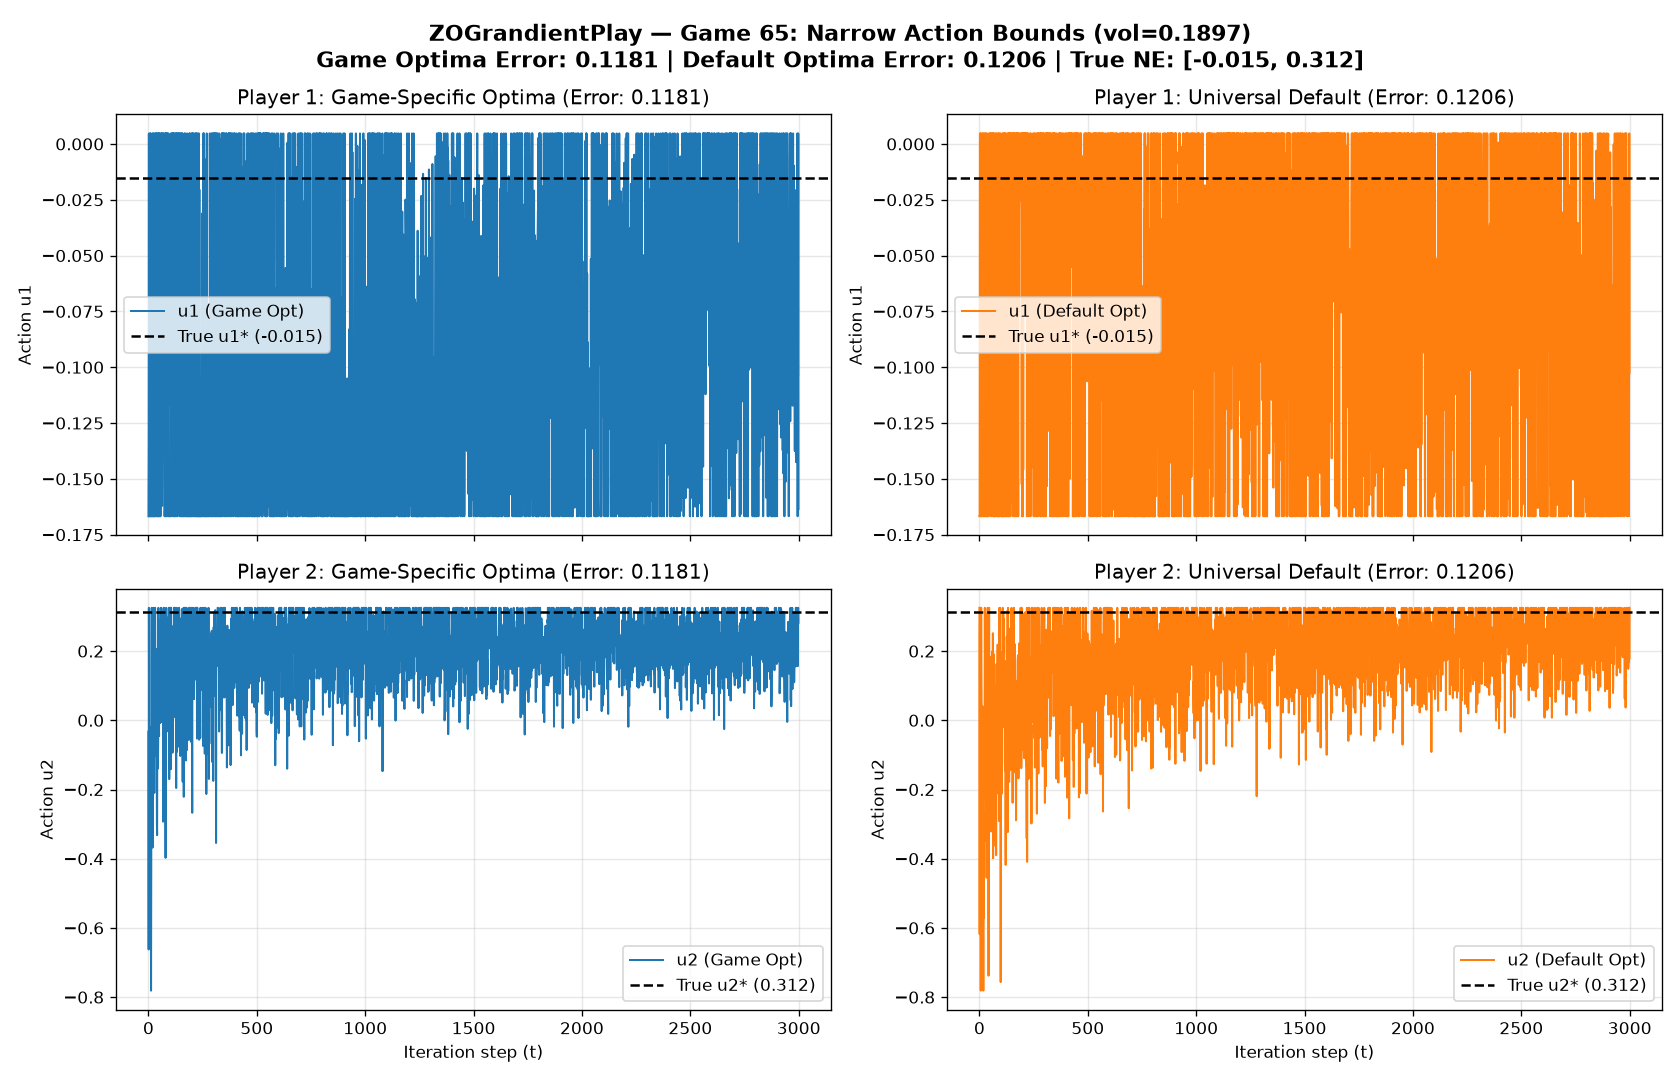

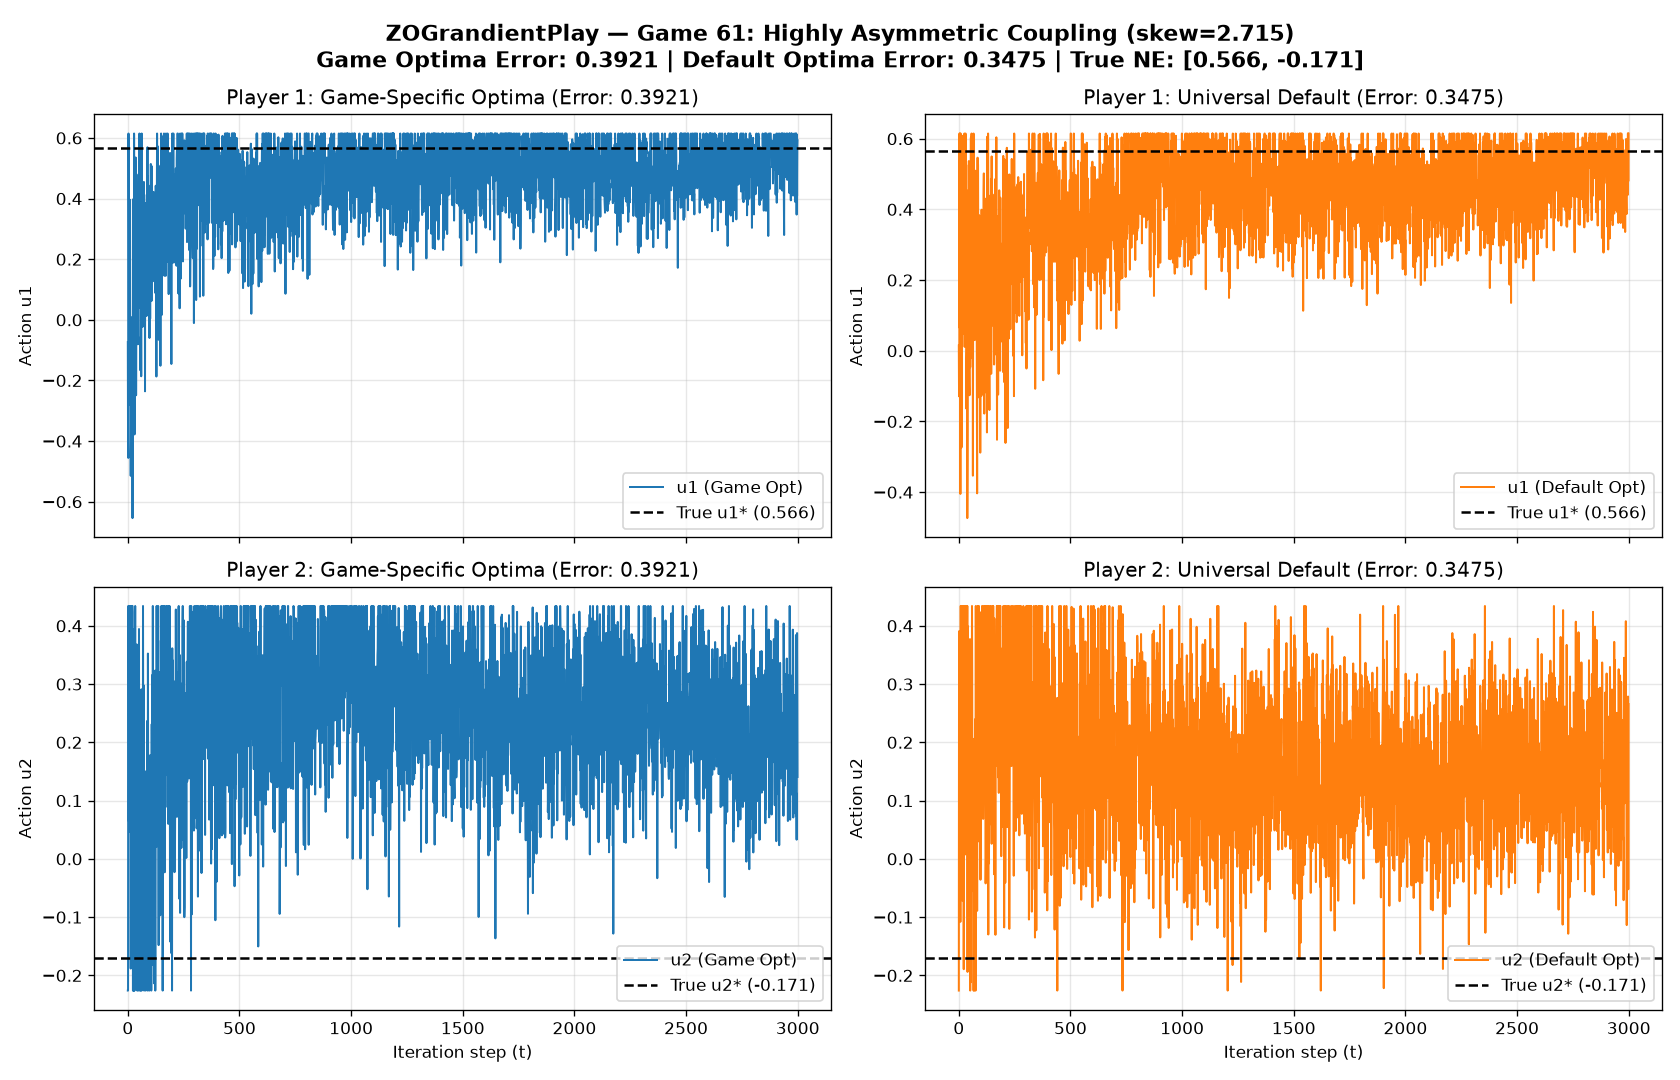

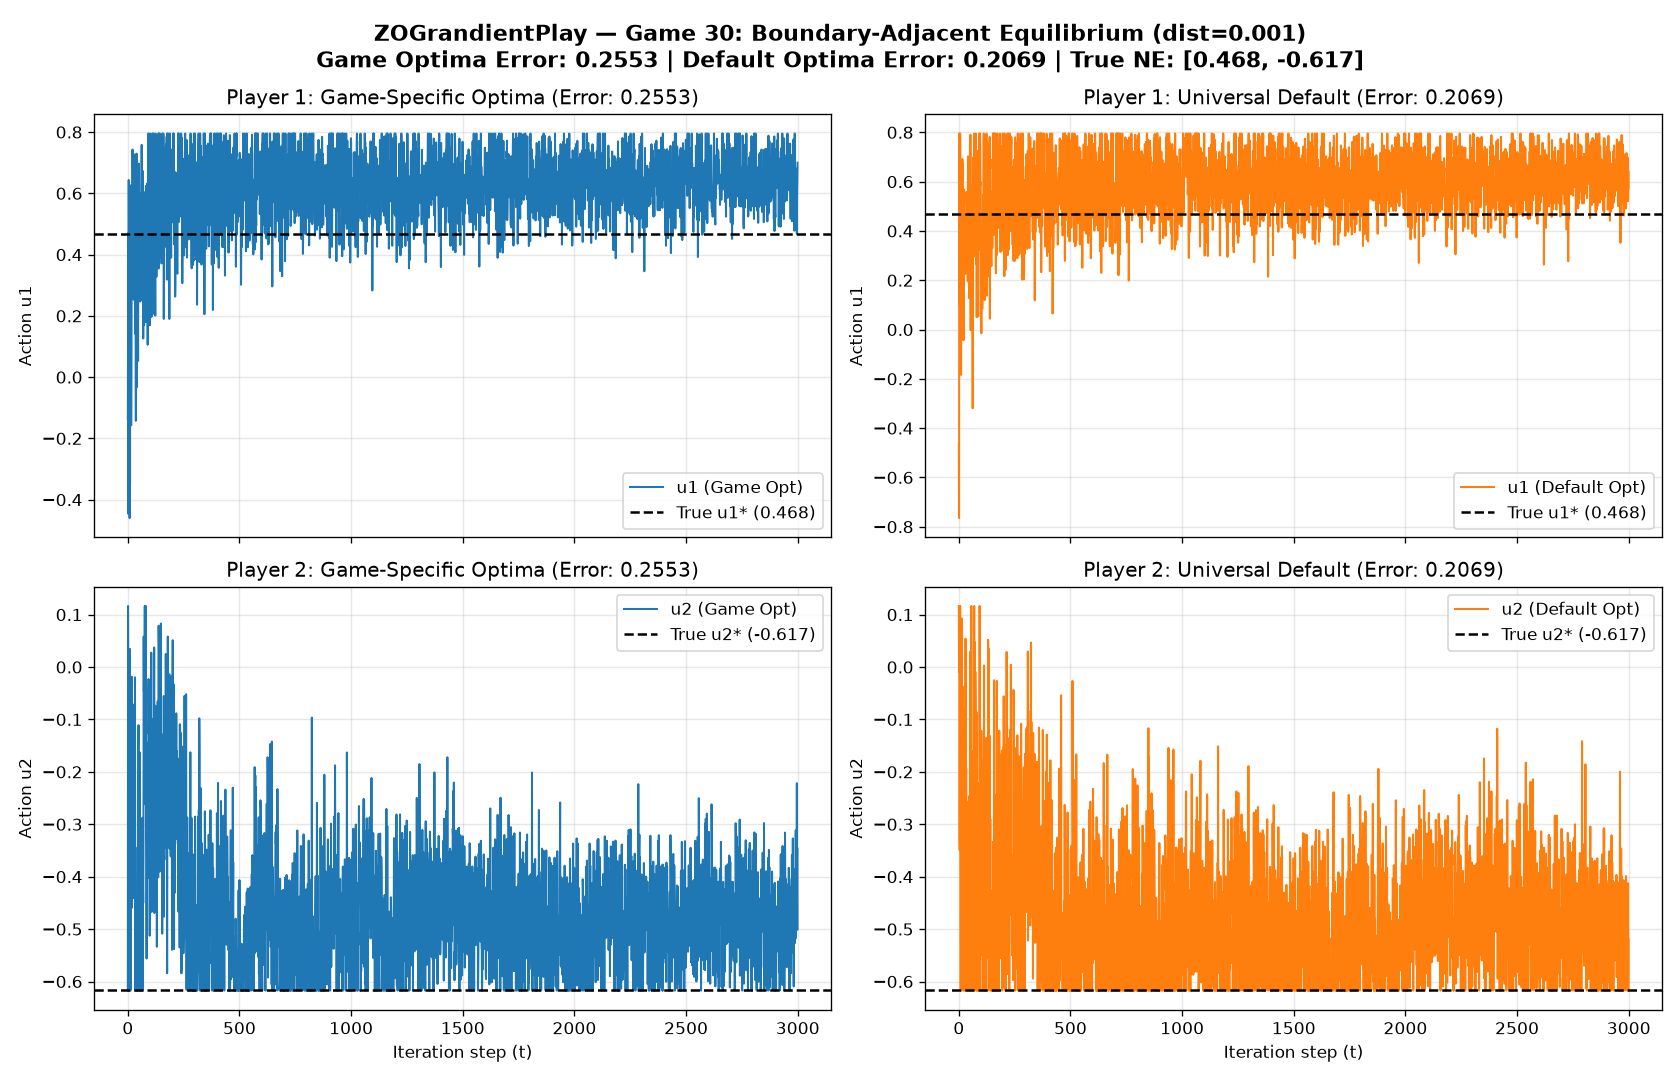

In [3]:
# 3. ZOGrandientPlay Action Trajectory Visualizations for 5 Representative Games (Actions Only)
num_iters = 3000

for g_idx, category, g in rep_games:
    opt_params = zo_opt._build_estimator_kwargs(zo_opt.best_thetas[g_idx], g)
    def_params = zo_opt._build_estimator_kwargs(zo_opt.best_theta_def, g)
    
    m = len(g.action_sets[0])
    init_actions = np.zeros((g.N, m), dtype=float)
    x_star = g.nash_equilibrium.ravel()
    
    est_opt = ZOGrandientPlay(g, **opt_params)
    _, hist_opt, _ = est_opt.estimate(init_actions, num_iters=num_iters)
    
    est_def = ZOGrandientPlay(g, **def_params)
    _, hist_def, _ = est_def.estimate(init_actions, num_iters=num_iters)
    
    err_opt = np.mean(np.linalg.norm(hist_opt[-50:] - x_star, axis=-1))
    err_def = np.mean(np.linalg.norm(hist_def[-50:] - x_star, axis=-1))
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
    fig.suptitle(
        f"ZOGrandientPlay (One-Point) — Game {g_idx}: {category}\n"
        f"Game Opt Error: {err_opt:.4f} | Default Opt Error: {err_def:.4f} | True NE: [{x_star[0]:.3f}, {x_star[1]:.3f}]",
        fontsize=12, fontweight="bold"
    )
    
    t_steps = np.arange(num_iters)
    # Row 0: Player 1
    axes[0, 0].plot(t_steps, hist_opt[:, 0], color="tab:blue", lw=1.2, label="u1 (Game Opt)")
    axes[0, 0].axhline(x_star[0], color="black", linestyle="--", lw=1.5, label=f"True u1* ({x_star[0]:.3f})")
    axes[0, 0].set_title(f"Player 1: Game Optima (Error: {err_opt:.4f})")
    axes[0, 0].set_ylabel("Action u1")
    axes[0, 0].grid(True, alpha=0.3)
    axes[0, 0].legend(loc="best")
    
    axes[0, 1].plot(t_steps, hist_def[:, 0], color="tab:orange", lw=1.2, label="u1 (Default Opt)")
    axes[0, 1].axhline(x_star[0], color="black", linestyle="--", lw=1.5, label=f"True u1* ({x_star[0]:.3f})")
    axes[0, 1].set_title(f"Player 1: Universal Default (Error: {err_def:.4f})")
    axes[0, 1].set_ylabel("Action u1")
    axes[0, 1].grid(True, alpha=0.3)
    axes[0, 1].legend(loc="best")
    
    # Row 1: Player 2
    axes[1, 0].plot(t_steps, hist_opt[:, 1], color="tab:blue", lw=1.2, label="u2 (Game Opt)")
    axes[1, 0].axhline(x_star[1], color="black", linestyle="--", lw=1.5, label=f"True u2* ({x_star[1]:.3f})")
    axes[1, 0].set_title(f"Player 2: Game Optima (Error: {err_opt:.4f})")
    axes[1, 0].set_xlabel("Iteration step (t)")
    axes[1, 0].set_ylabel("Action u2")
    axes[1, 0].grid(True, alpha=0.3)
    axes[1, 0].legend(loc="best")
    
    axes[1, 1].plot(t_steps, hist_def[:, 1], color="tab:orange", lw=1.2, label="u2 (Default Opt)")
    axes[1, 1].axhline(x_star[1], color="black", linestyle="--", lw=1.5, label=f"True u2* ({x_star[1]:.3f})")
    axes[1, 1].set_title(f"Player 2: Universal Default (Error: {err_def:.4f})")
    axes[1, 1].set_xlabel("Iteration step (t)")
    axes[1, 1].set_ylabel("Action u2")
    axes[1, 1].grid(True, alpha=0.3)
    axes[1, 1].legend(loc="best")
    
    plt.tight_layout()
    plt.show()


In [4]:
# 4. NESeeking MTBO (Continuous-Time Extremum Seeking)
ne_search_space = {"k": (0.1, 5.0), "a": (0.01, 0.5)}
ne_fixed_params = {
    "omega": np.array([[25.0], [31.0]]),
    "phi": np.array([[0.0], [0.0]]),
    "dt": 0.005,
}

ne_opt = MetaParamOptimization(
    game_ensemble=games,
    search_space=ne_search_space,
    algorithm_class=NESeeking,
    output_path="ne_optimal_metaparams.csv",
    num_iters=3000,
    smoothing_window=50,
    n_init=100,
    n_bo_steps=700,
    seed=42,
    fixed_params=ne_fixed_params,
)

ne_results = ne_opt.run_optimization_loop()
print("NESeeking MTBO complete.")
print("Universal default theta (average):", ne_results[-1])


NESeeking MTBO complete.
Universal default theta (average): {'game_id': 'default', 'is_default': True, 'omega[0,0]': 25.0, 'omega[1,0]': 31.0, 'phi[0,0]': 0.0, 'phi[1,0]': 0.0, 'dt': 0.005, 'k[0,0]': 4.639271182082884, 'k[1,0]': 4.639271182082884, 'a[0,0]': 0.30357051539535107, 'a[1,0]': 0.30357051539535107, 'objective_value': 0.3582}


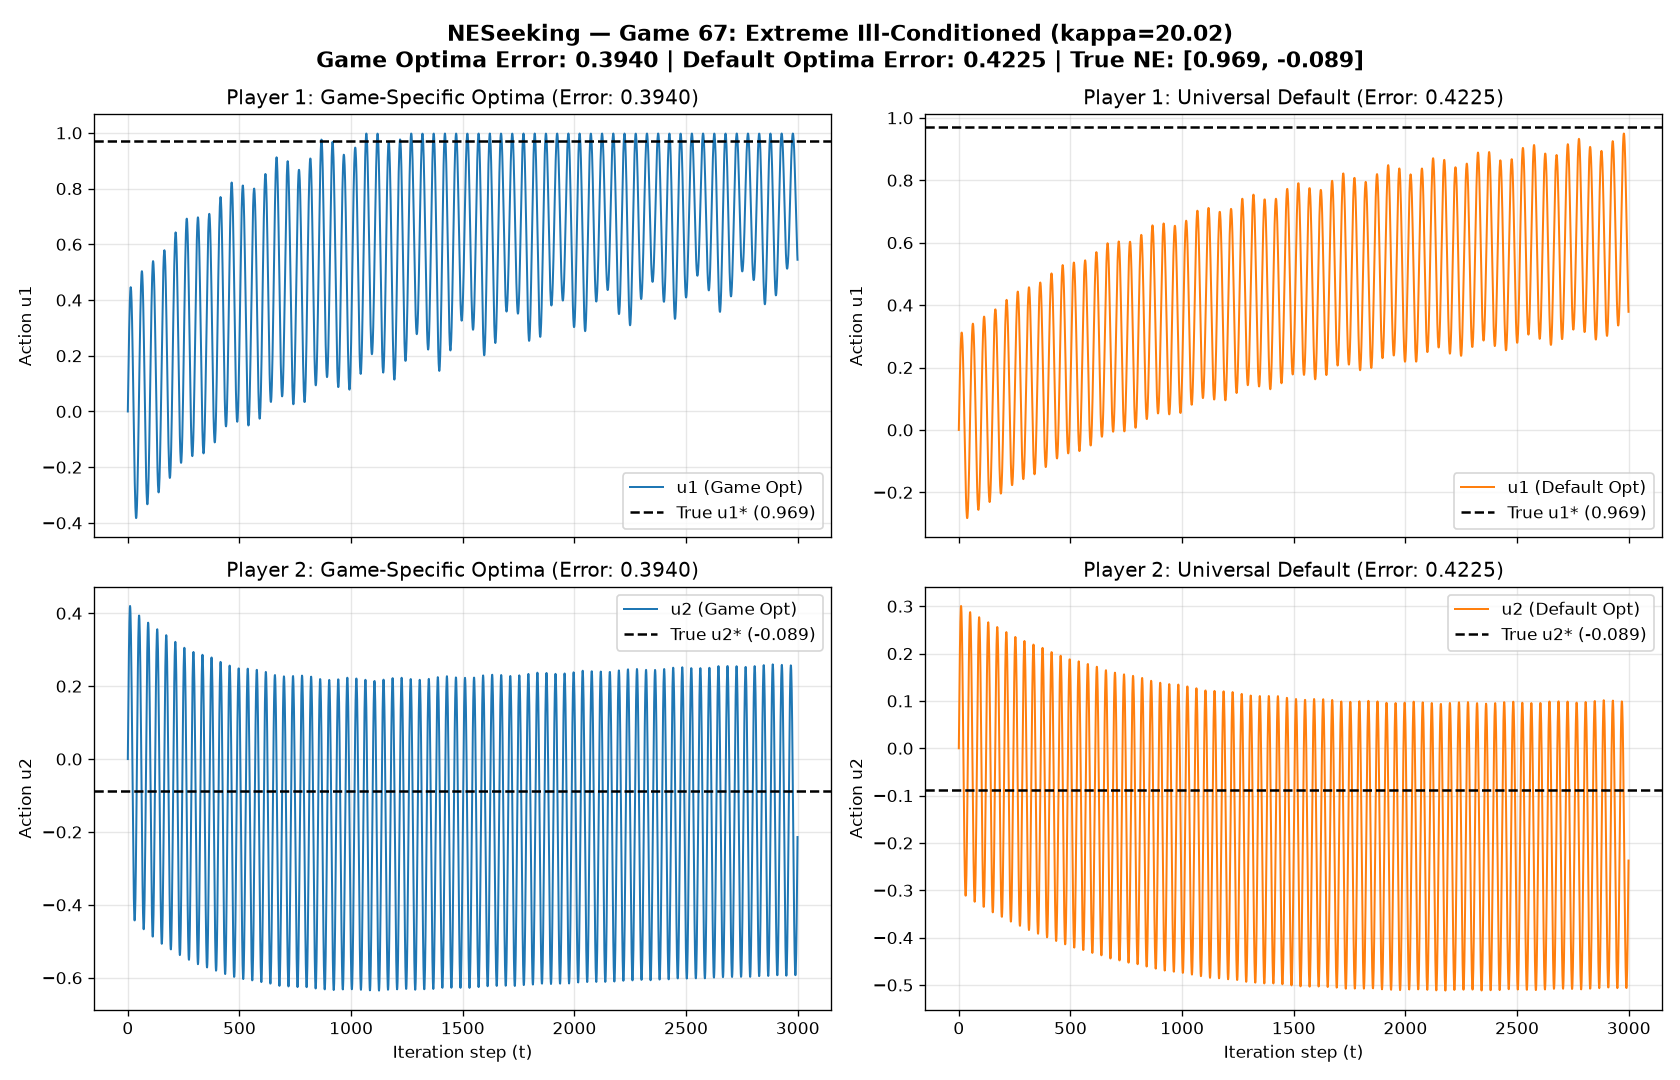

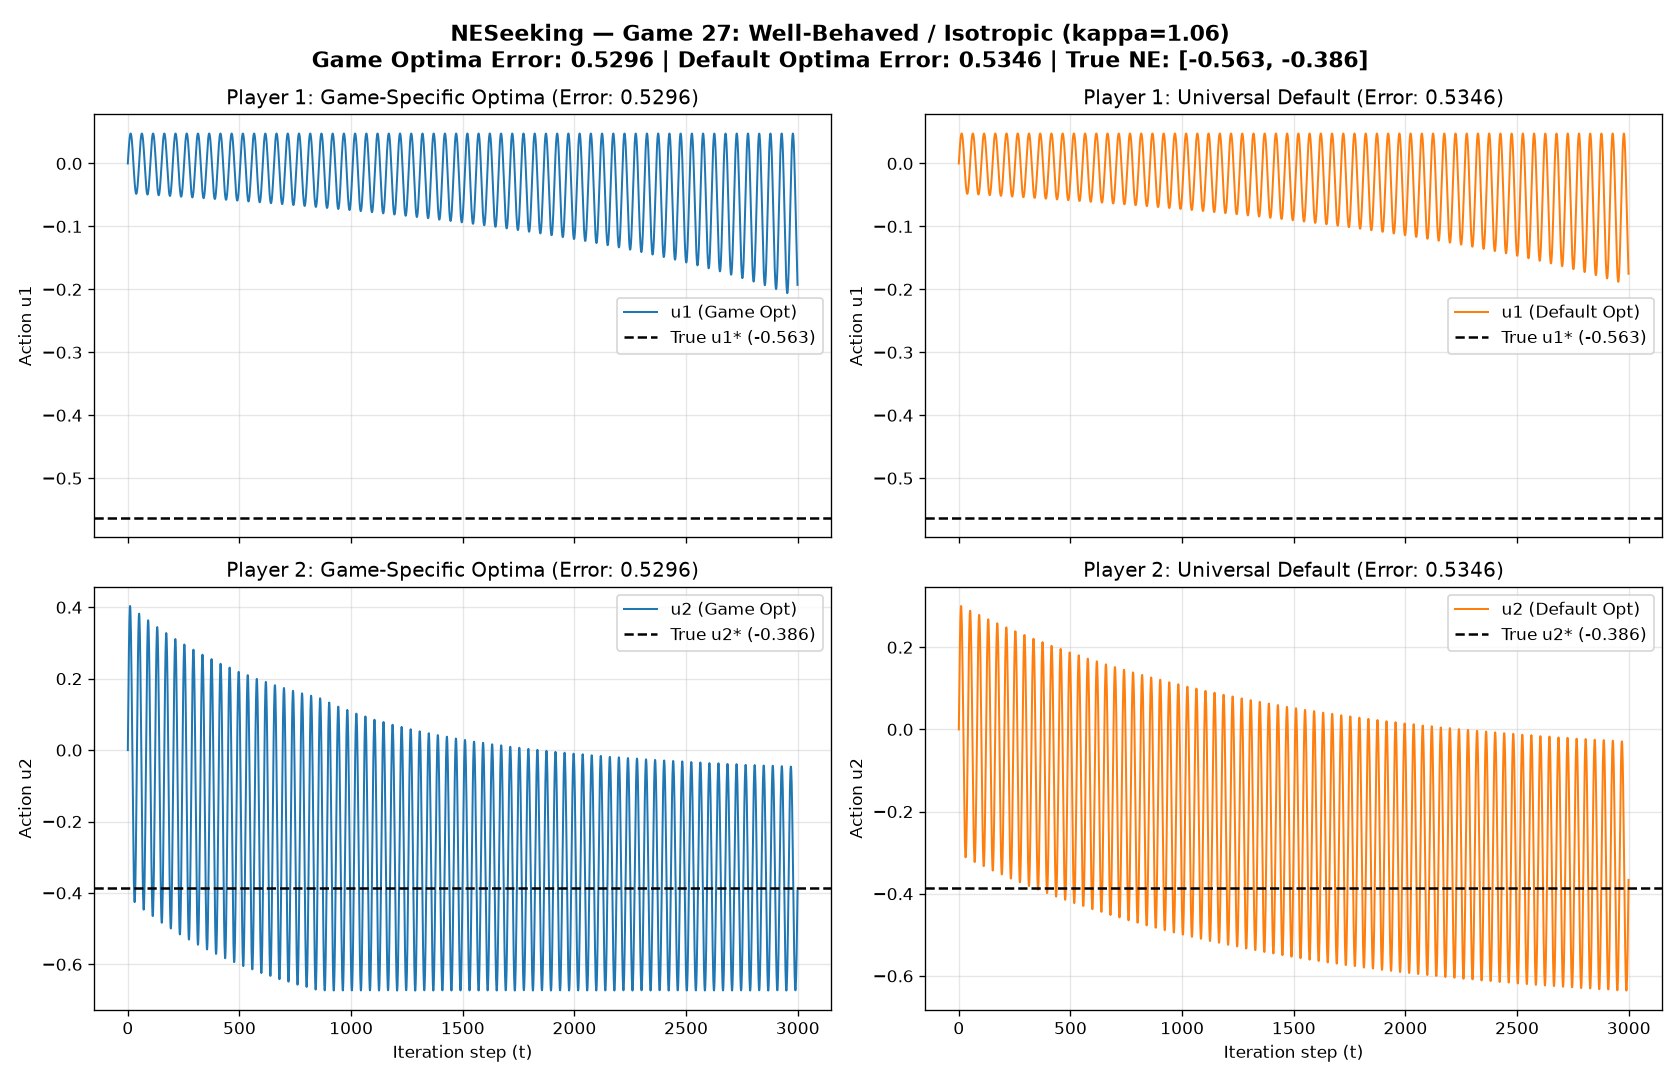

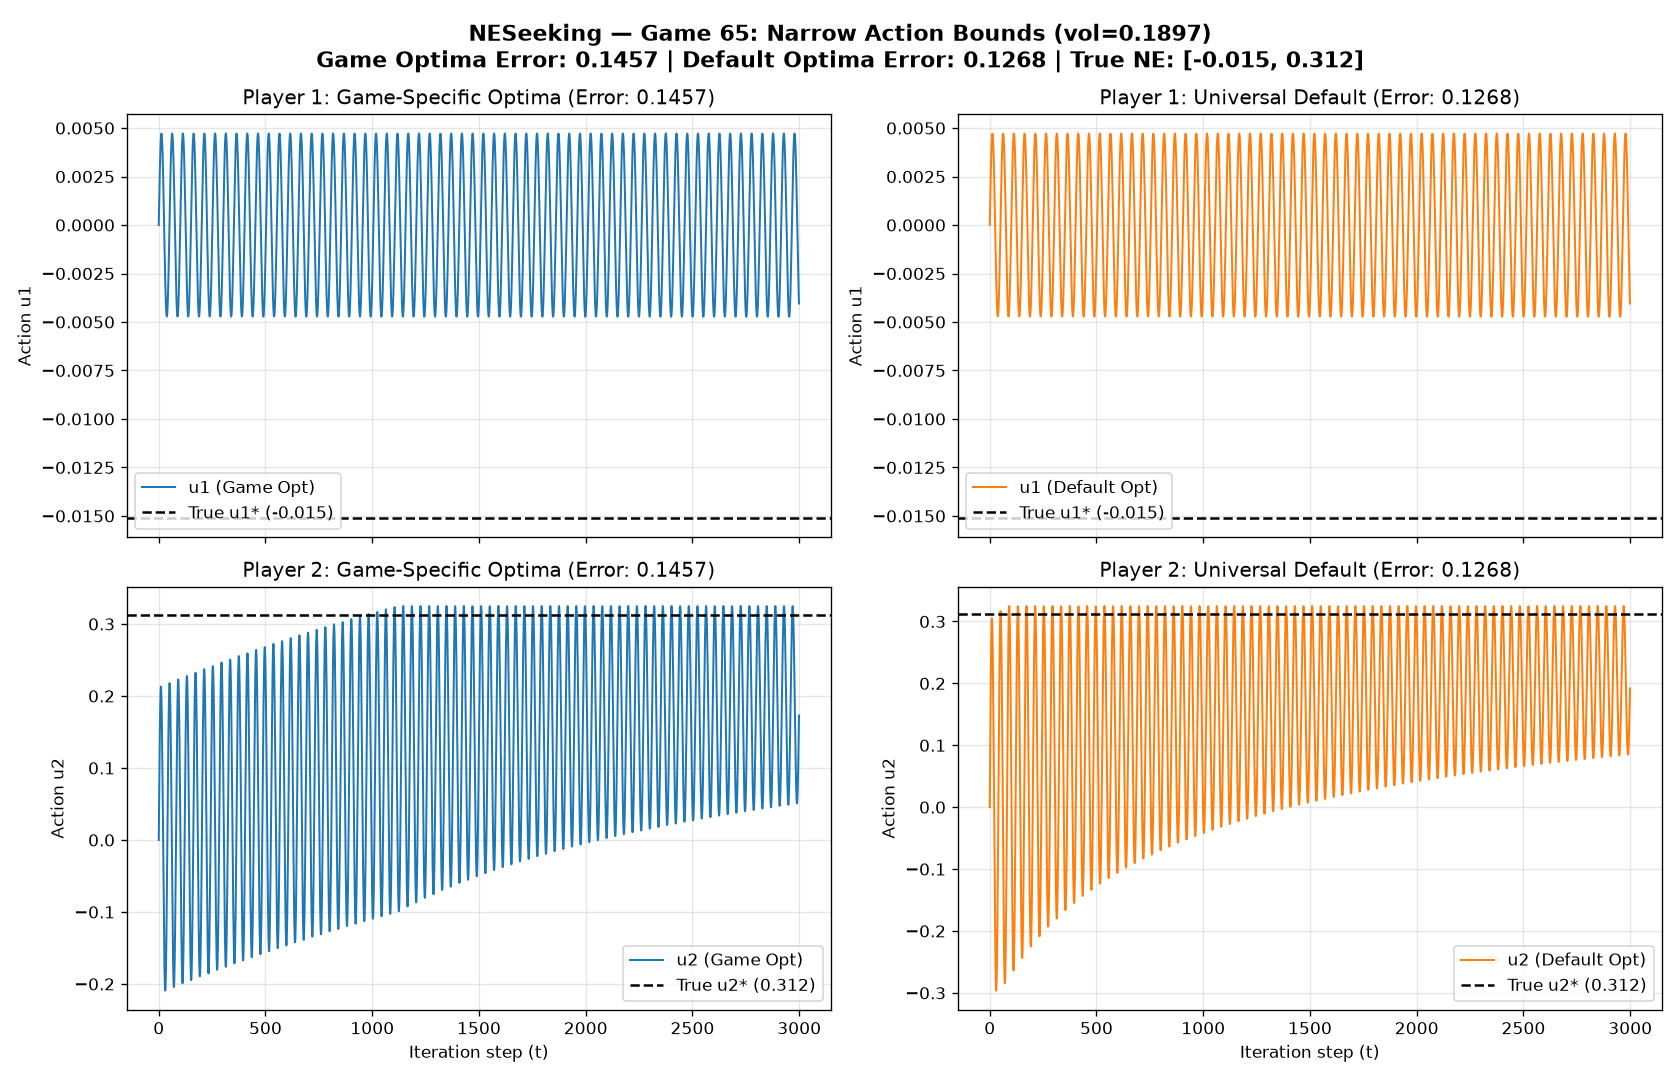

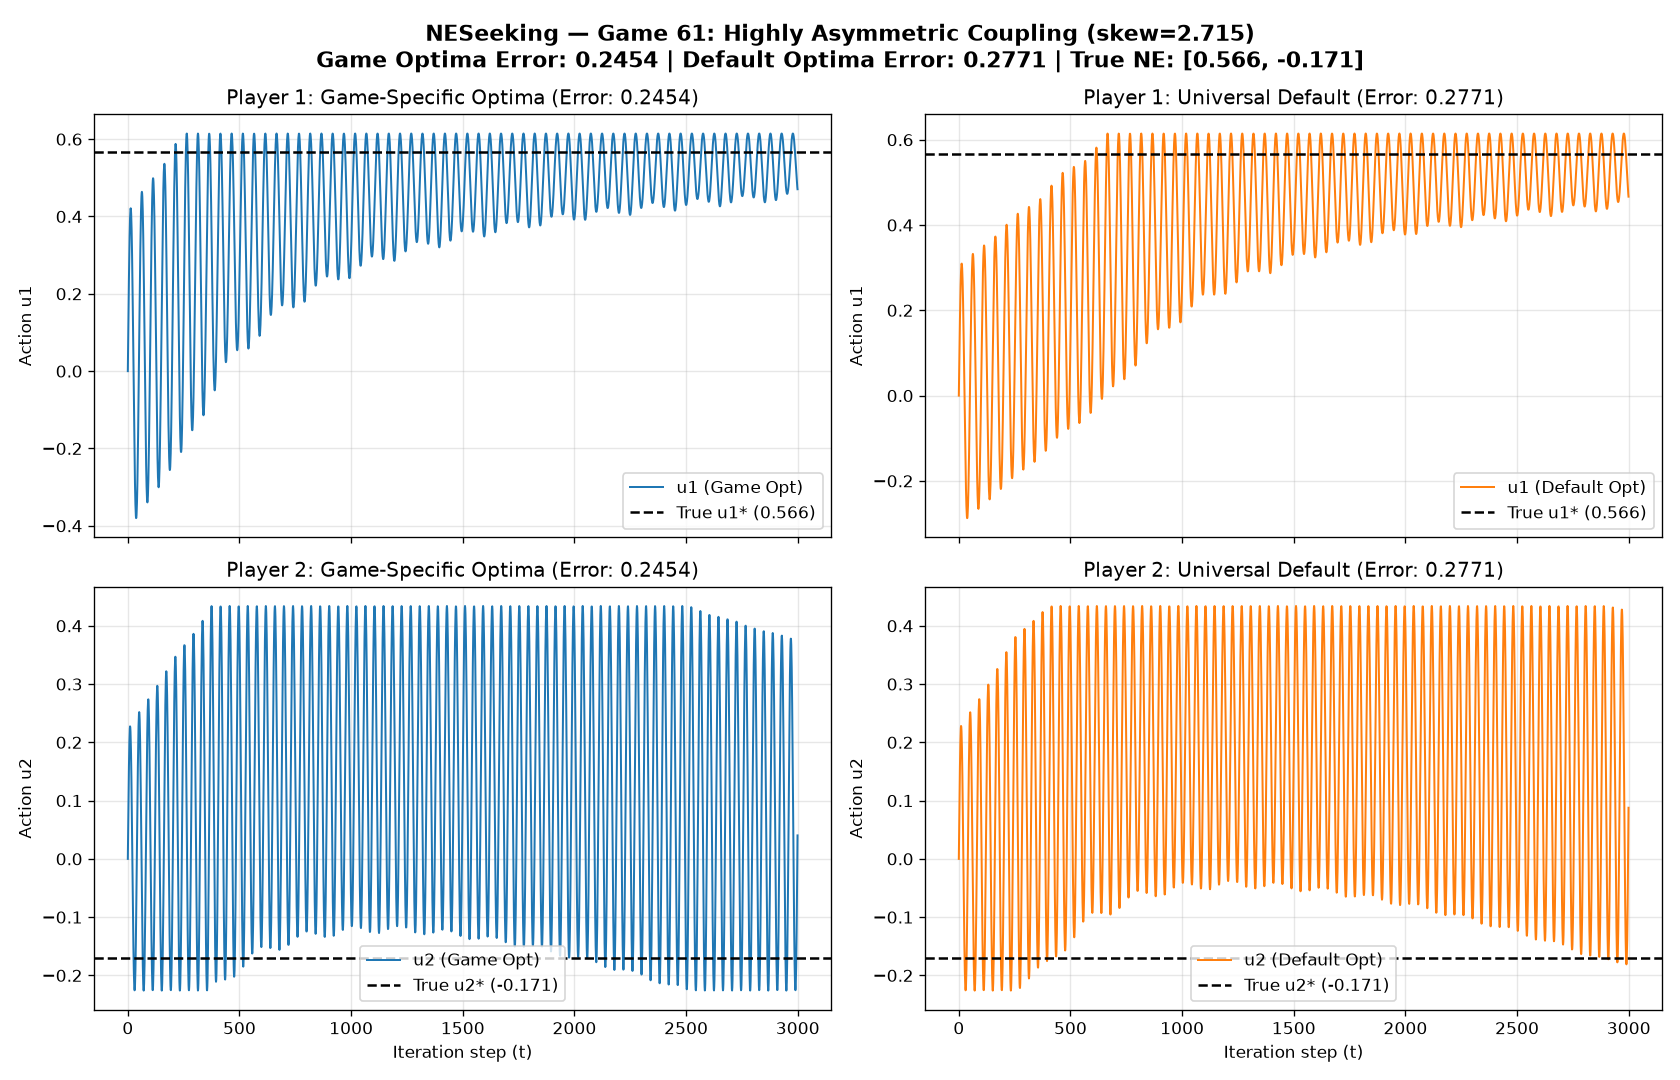

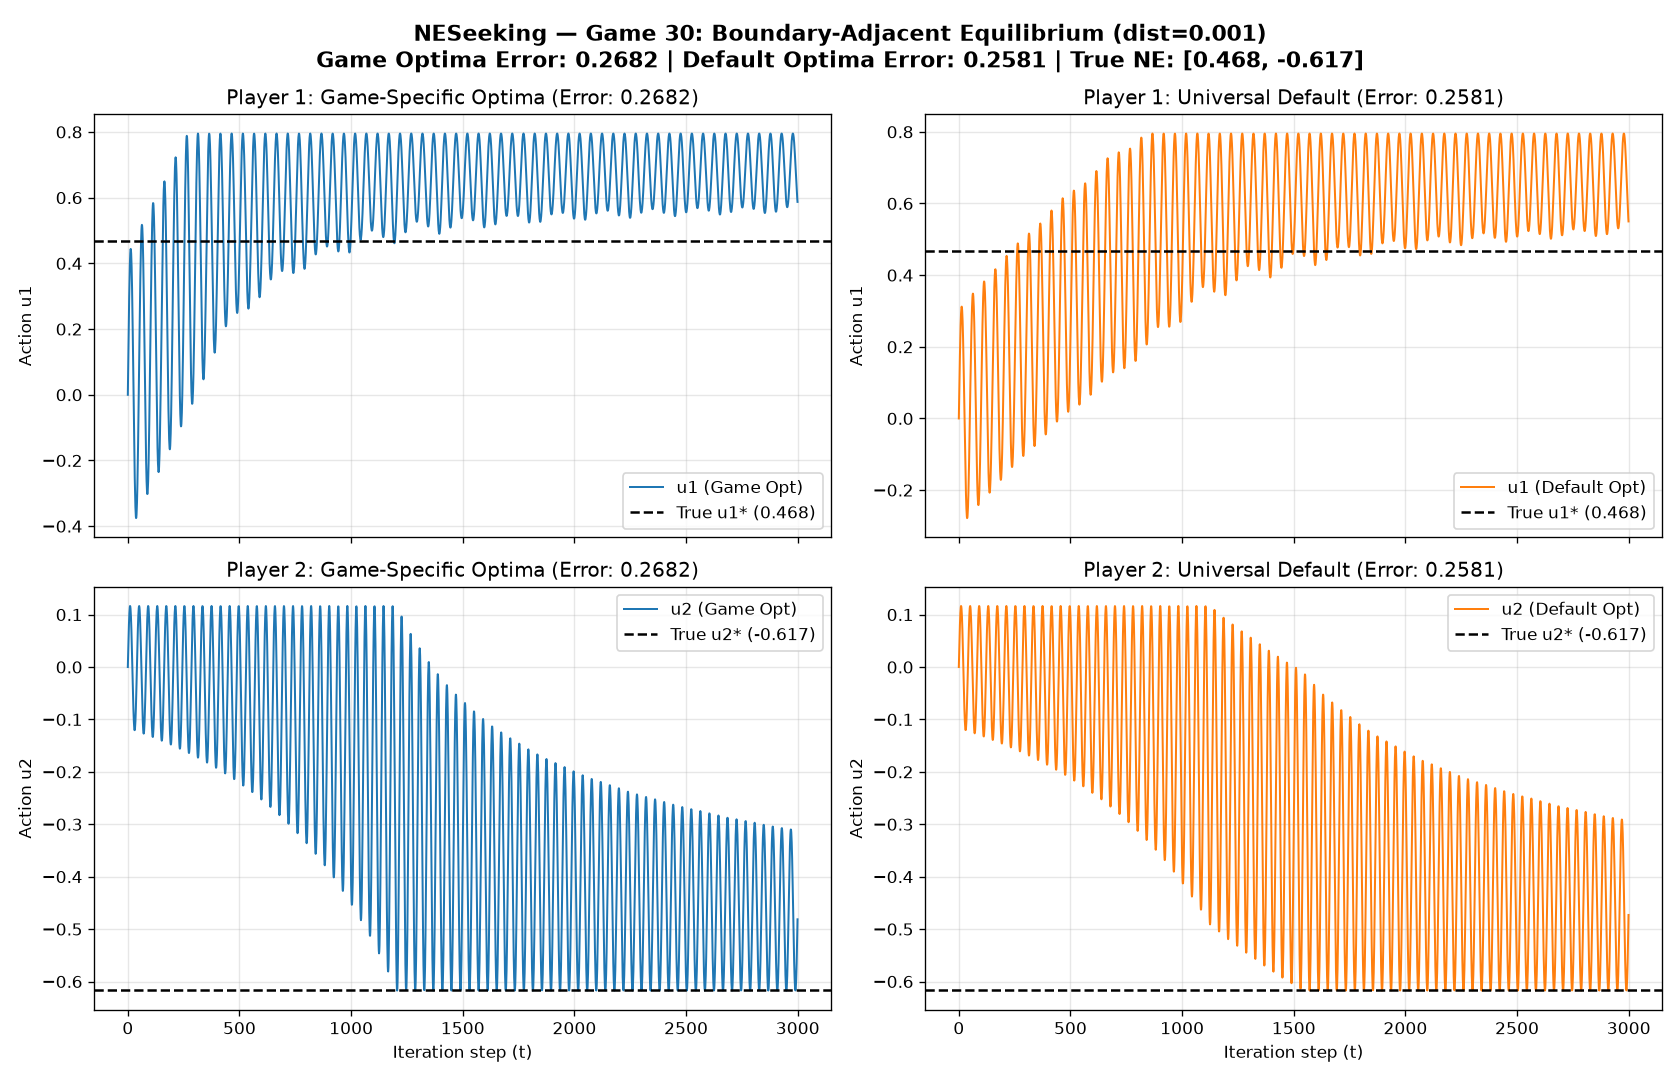

In [5]:
# 5. NESeeking Action Trajectory Visualizations for 5 Representative Games (Actions Only)
for g_idx, category, g in rep_games:
    opt_params = ne_opt._build_estimator_kwargs(ne_opt.best_thetas[g_idx], g)
    def_params = ne_opt._build_estimator_kwargs(ne_opt.best_theta_def, g)
    
    m = len(g.action_sets[0])
    init_actions = np.zeros((g.N, m), dtype=float)
    x_star = g.nash_equilibrium.ravel()
    
    est_opt = NESeeking(g, **opt_params)
    _, hist_opt, _ = est_opt.estimate(init_actions, num_iters=num_iters)
    
    est_def = NESeeking(g, **def_params)
    _, hist_def, _ = est_def.estimate(init_actions, num_iters=num_iters)
    
    err_opt = np.mean(np.linalg.norm(hist_opt[-50:] - x_star, axis=-1))
    err_def = np.mean(np.linalg.norm(hist_def[-50:] - x_star, axis=-1))
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
    fig.suptitle(
        f"NESeeking — Game {g_idx}: {category}\n"
        f"Game Opt Error: {err_opt:.4f} | Default Opt Error: {err_def:.4f} | True NE: [{x_star[0]:.3f}, {x_star[1]:.3f}]",
        fontsize=12, fontweight="bold"
    )
    
    t_steps = np.arange(num_iters)
    # Row 0: Player 1
    axes[0, 0].plot(t_steps, hist_opt[:, 0], color="tab:blue", lw=1.2, label="u1 (Game Opt)")
    axes[0, 0].axhline(x_star[0], color="black", linestyle="--", lw=1.5, label=f"True u1* ({x_star[0]:.3f})")
    axes[0, 0].set_title(f"Player 1: Game Optima (Error: {err_opt:.4f})")
    axes[0, 0].set_ylabel("Action u1")
    axes[0, 0].grid(True, alpha=0.3)
    axes[0, 0].legend(loc="best")
    
    axes[0, 1].plot(t_steps, hist_def[:, 0], color="tab:orange", lw=1.2, label="u1 (Default Opt)")
    axes[0, 1].axhline(x_star[0], color="black", linestyle="--", lw=1.5, label=f"True u1* ({x_star[0]:.3f})")
    axes[0, 1].set_title(f"Player 1: Universal Default (Error: {err_def:.4f})")
    axes[0, 1].set_ylabel("Action u1")
    axes[0, 1].grid(True, alpha=0.3)
    axes[0, 1].legend(loc="best")
    
    # Row 1: Player 2
    axes[1, 0].plot(t_steps, hist_opt[:, 1], color="tab:blue", lw=1.2, label="u2 (Game Opt)")
    axes[1, 0].axhline(x_star[1], color="black", linestyle="--", lw=1.5, label=f"True u2* ({x_star[1]:.3f})")
    axes[1, 0].set_title(f"Player 2: Game Optima (Error: {err_opt:.4f})")
    axes[1, 0].set_xlabel("Iteration step (t)")
    axes[1, 0].set_ylabel("Action u2")
    axes[1, 0].grid(True, alpha=0.3)
    axes[1, 0].legend(loc="best")
    
    axes[1, 1].plot(t_steps, hist_def[:, 1], color="tab:orange", lw=1.2, label="u2 (Default Opt)")
    axes[1, 1].axhline(x_star[1], color="black", linestyle="--", lw=1.5, label=f"True u2* ({x_star[1]:.3f})")
    axes[1, 1].set_title(f"Player 2: Universal Default (Error: {err_def:.4f})")
    axes[1, 1].set_xlabel("Iteration step (t)")
    axes[1, 1].set_ylabel("Action u2")
    axes[1, 1].grid(True, alpha=0.3)
    axes[1, 1].legend(loc="best")
    
    plt.tight_layout()
    plt.show()


In [6]:
# 6. Quantitative Evaluation across All 100 Games & Comparative Report
zo_errors_opt = np.array([zo_opt.evaluate_task(zo_opt.best_thetas[j], j) for j in range(len(games))])
zo_errors_def = np.array([zo_opt.evaluate_task(zo_opt.best_theta_def, j) for j in range(len(games))])
ne_errors_opt = np.array([ne_opt.evaluate_task(ne_opt.best_thetas[j], j) for j in range(len(games))])
ne_errors_def = np.array([ne_opt.evaluate_task(ne_opt.best_theta_def, j) for j in range(len(games))])

zo_delta = zo_errors_def - zo_errors_opt
ne_delta = ne_errors_def - ne_errors_opt

print("=== Summary of 5 Representative Games ===")
for g_idx, category, g in rep_games:
    u_star = g.nash_equilibrium.ravel()
    print(f"Game {g_idx} ({category}):")
    print(f"  True NE: [{u_star[0]:.3f}, {u_star[1]:.3f}]")
    print(f"  ZOGP Error: Tailored={zo_errors_opt[g_idx]:.4f}, Default={zo_errors_def[g_idx]:.4f}, Delta={zo_delta[g_idx]:.4f}")
    print(f"  NES Error:  Tailored={ne_errors_opt[g_idx]:.4f}, Default={ne_errors_def[g_idx]:.4f}, Delta={ne_delta[g_idx]:.4f}\n")

print("=== Ensemble Statistics across All 100 Games ===")
print(f"ZO Error with Tailored Optima: Mean = {np.mean(zo_errors_opt):.4f} +/- {np.std(zo_errors_opt):.4f}, Median = {np.median(zo_errors_opt):.4f}")
print(f"ZO Error with Universal Default: Mean = {np.mean(zo_errors_def):.4f} +/- {np.std(zo_errors_def):.4f}, Median = {np.median(zo_errors_def):.4f}")
print(f"ZO Tunability Gain (Def - Opt): Mean = {np.mean(zo_delta):.4f}, Max = {np.max(zo_delta):.4f}\n")
print(f"NE Error with Tailored Optima: Mean = {np.mean(ne_errors_opt):.4f} +/- {np.std(ne_errors_opt):.4f}, Median = {np.median(ne_errors_opt):.4f}")
print(f"NE Error with Universal Default: Mean = {np.mean(ne_errors_def):.4f} +/- {np.std(ne_errors_def):.4f}, Median = {np.median(ne_errors_def):.4f}")
print(f"NE Tunability Gain (Def - Opt): Mean = {np.mean(ne_delta):.4f}, Max = {np.max(ne_delta):.4f}")


=== Summary of 5 Representative Games ===
Game 67 (Extreme Ill-Conditioned (kappa=20.02)):
  True NE: [0.969, -0.089]
  ZOGP Error: Tailored=0.1949, Default=0.1499, Delta=-0.0450
  NES Error:  Tailored=0.3940, Default=0.4225, Delta=0.0286

Game 27 (Well-Behaved / Isotropic (kappa=1.06)):
  True NE: [-0.563, -0.386]
  ZOGP Error: Tailored=0.1127, Default=0.1242, Delta=0.0115
  NES Error:  Tailored=0.5296, Default=0.5346, Delta=0.0050

Game 65 (Narrow Action Bounds (vol=0.1897)):
  True NE: [-0.015, 0.312]
  ZOGP Error: Tailored=0.1985, Default=0.1328, Delta=-0.0657
  NES Error:  Tailored=0.1457, Default=0.1268, Delta=-0.0189

Game 61 (Highly Asymmetric Coupling (skew=2.715)):
  True NE: [0.566, -0.171]
  ZOGP Error: Tailored=0.2593, Default=0.4098, Delta=0.1505
  NES Error:  Tailored=0.2454, Default=0.2771, Delta=0.0318

Game 30 (Boundary-Adjacent Equilibrium (dist=0.001)):
  True NE: [0.468, -0.617]
  ZOGP Error: Tailored=0.3905, Default=0.2716, Delta=-0.1190
  NES Error:  Tailored=0.2